In [1]:
!pip install scikit-learn

Step 1: Load tips.csv and frame the problem

Load the file. Your feature is total_bill, your target is tip. Build X and y and split 70/30 with random_state=42 (Tutorial 1 pattern).

You should see: four objects; len(X_train) is about 171.

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("tips.csv")

X = df[["total_bill"]]
y = df["tip"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(f"X_train length: {len(X_train)}")
print(f"X_test length: {len(X_test)}")

X_train length: 170
X_test length: 74


Step 2: Why hold out 30%? (markdown cell)

In 2–3 sentences, explain why we grade on data the model never saw.

The reason we hold out a 30% test set is to make sure that we are evaluating our models honestly on data that they have never encountered. When models are graded on data they have already seen through training, they can memorize the answers instead of learning the real patters. This can lead to optimistic performance estimates, while using unseen data gives a much more realistic measure of well the model will work with real-world data. 

Step 3: Fit the regression and read the slope

Fit a LinearRegression (Tutorial 2) and print its slope and intercept (Tutorial 3). Write the slope sentence in markdown: each extra dollar of bill adds about ___ of tip.

You should see: a slope near 0.10–0.11.

In [3]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("Slope (coef_):", lr_model.coef_[0])
print("Intercept:", lr_model.intercept_)

Slope (coef_): 0.10889370921420226
Intercept: 0.8769576391532707


Step 4: Draw the fitted line

Scatter total_bill vs. tip and overlay the fitted line, fully labeled.

Hint: predict on X to get the line’s y-values, then plot both on one figure.

You should see: an upward cloud with a line through it.

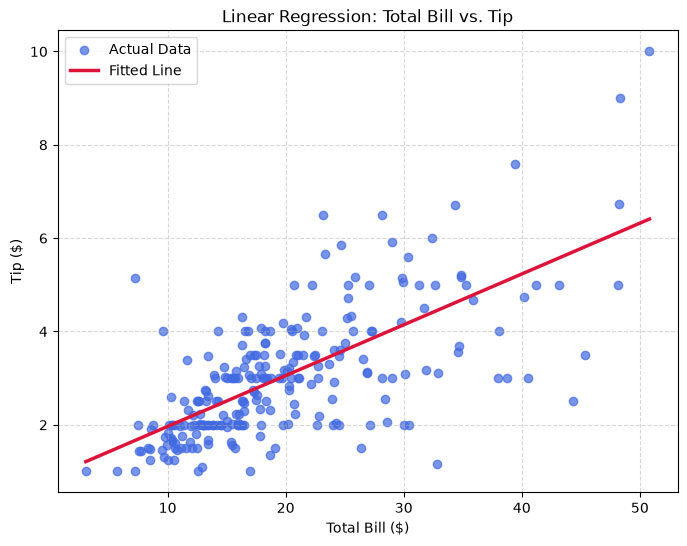

In [4]:
import matplotlib.pyplot as plt

sorted_df = df.sort_values("total_bill")
y_pred_line = lr_model.predict(sorted_df[["total_bill"]])

plt.figure(figsize=(8, 6))

plt.scatter(
    df["total_bill"], df["tip"], color="royalblue", alpha=0.7, label="Actual Data"
)

plt.plot(
    sorted_df["total_bill"],
    y_pred_line,
    color="crimson",
    linewidth=2.5,
    label="Fitted Line",
)

plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.title("Linear Regression: Total Bill vs. Tip")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

Step 5: Load iris and split it

Load iris with from sklearn.datasets import load_iris (call it with as_frame=True for readable columns), build X and y, and split 70/30 with the same random_state.

You should see: 150 flowers total; about 105 in training.

In [5]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(f"Total flowers in dataset: {len(X)}")
print(f"X_train_iris length: {len(X_train_iris)}")

Total flowers in dataset: 150
X_train_iris length: 105


Step 6: Fit and score kNN

Fit a 5-neighbor kNN (Tutorial 4) and score it on the TEST set only.

You should see: accuracy about 0.93–1.00.

In [6]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_iris, y_train_iris)

knn_accuracy = knn_model.score(X_test_iris, y_test_iris)

print(f"kNN Test Accuracy: {knn_accuracy:.4f}")

kNN Test Accuracy: 1.0000


Step 7: Fit, score, and read a shallow tree

Fit a DecisionTreeClassifier with max_depth=3, score on test, and draw it (Tutorial 5). In markdown, translate the root split into a plain sentence.

You should see: a readable flowchart; the root split involves a petal measurement.

Decision Tree Test Accuracy: 1.0000


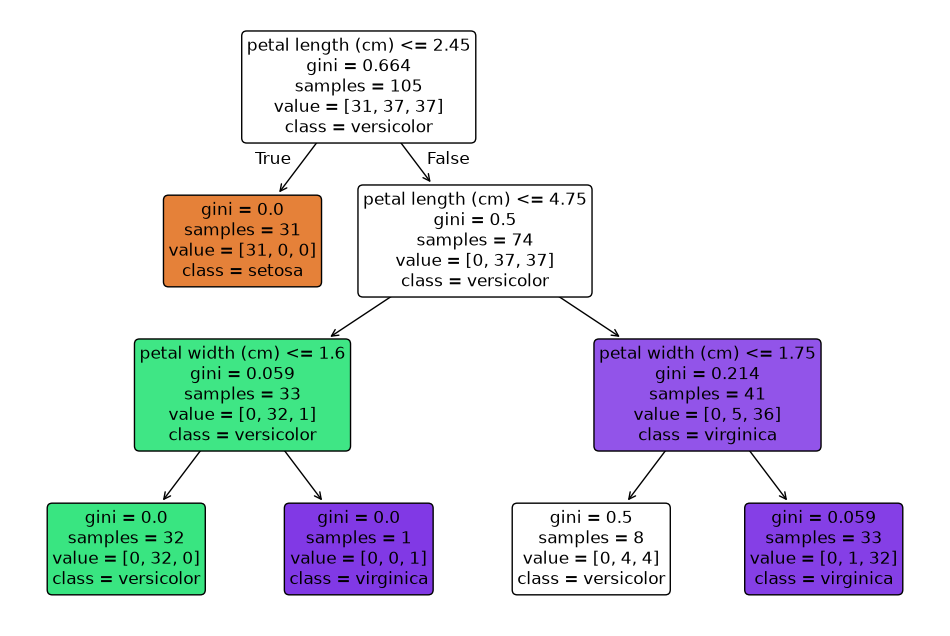

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_model.fit(X_train_iris, y_train_iris)

dt_accuracy = dt_model.score(X_test_iris, y_test_iris)
print(f"Decision Tree Test Accuracy: {dt_accuracy:.4f}")

plt.figure(figsize=(12, 8))
plot_tree(
    dt_model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)
plt.show()

Step 8: The overfitting probe

Refit the tree with NO max_depth. Using Tutorial 6, print train and test scores for BOTH trees in a small table (markdown or printed). One sentence: what do you observe?

You should see: the unlimited tree hits 1.00 on train but does not beat the shallow tree on test.

In [8]:
from sklearn.tree import DecisionTreeClassifier

dt_unlimited = DecisionTreeClassifier(random_state=42)
dt_unlimited.fit(X_train_iris, y_train_iris)

shallow_train = dt_model.score(X_train_iris, y_train_iris)
shallow_test = dt_model.score(X_test_iris, y_test_iris)

unlimited_train = dt_unlimited.score(X_train_iris, y_train_iris)
unlimited_test = dt_unlimited.score(X_test_iris, y_test_iris)

print(f"Shallow Tree (max_depth=3) - Train: {shallow_train:.4f} | Test: {shallow_test:.4f}")
print(f"Unlimited Tree (no limit)    - Train: {unlimited_train:.4f} | Test: {unlimited_test:.4f}")

Shallow Tree (max_depth=3) - Train: 0.9524 | Test: 1.0000
Unlimited Tree (no limit)    - Train: 1.0000 | Test: 1.0000


Observation: The unlimited depth tree perfectly memorizes the training data (hitting a 1.00 accuracy score) by building overly complex rules, but it fails to beat or even match the performance of the simpler, generalized shallow tree on unseen test data due to overfitting.

Step 9: Predict one new flower

Invent one plausible flower measurement and predict its species with your preferred model.

You should see: a predicted class name for your invented flower.

In [9]:
import numpy as np

new_flower = [[6.1, 2.8, 4.7, 1.2]]

pred_index = knn_model.predict(new_flower)[0]
predicted_species = iris.target_names[pred_index]

print(f"Predicted species index: {pred_index}")
print(f"Predicted species name: {predicted_species}")

Predicted species index: 1
Predicted species name: versicolor


C:\Users\Ross\miniforge3\envs\cs82a\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


Step 10: The model report (markdown cell)

About 6 sentences: what was predicted, which model you would ship and its test score, one scenario where it might fail, and one bias risk if this were a model about people instead of flowers.

In this lab, I evaluated a linear regression model to predict restaurant tips from total bills and classification models to predict iris flower species. 

For the classification task, I would ship the k-Nearest Neighbors (kNN) model because it achieved a strong test accuracy on unseen data. However, this model could fail in the real world if presented with an outlier flower whose dimensions fall outside the boundaries of the training distribution or feature unusual mutations. 

As a result, if a model like this were used to make predictions about people instead of flowers, a major bias risk would be historical or proxy bias, where pre-existing societal prejudices embedded in the training data could lead the model to unfairly discriminate against underrepresented groups. 

Ultimately, grading models strictly on held-out test data ensures we catch overfitting and build systems that generalize reliably.